<a href="https://colab.research.google.com/github/CharlizeCo/dsc490_hockey_capstone/blob/main/dsc490_hockey_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Import the Dataset from SportsDataverse

In [1]:
pip install sportsdataverse

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 8.4 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 993.3/993.3 kB 4.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 5.7 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 6.0 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [sportsdataverse]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [2]:
import sportsdataverse.pwhl
import sportsdataverse.nhl

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
from sportsdataverse import pwhl
import pandas as pd
from sportsdataverse.pwhl import (
    load_pwhl_game_info, load_pwhl_team_boxscores, load_pwhl_schedules, load_pwhl_scoring_summary
)
from sportsdataverse.nhl import (
    load_nhl_game_info, load_nhl_team_boxscores
)

# Define what to load per league
pwhl_2026 = {
    "game_info": load_pwhl_game_info(2026),
    "team_boxscores": load_pwhl_team_boxscores(2026),
    "scoring_summary": load_pwhl_scoring_summary(2026),
    #"schedules": load_pwhl_schedules(2026)
}

nhl_2026 = {
    "game_info": load_nhl_game_info(2026),
    "player_boxscores":load_nhl_team_boxscores(2026),
}

pwhl_2025 = {
    "game_info": load_pwhl_game_info(2025),
    "team_boxscores": load_pwhl_team_boxscores(2025),
    "scoring_summary": load_pwhl_scoring_summary(2025),
    #"schedules": load_pwhl_schedules(2025)
}

nhl_2025 = {
    "game_info": load_nhl_game_info(2025),
    "goalie_boxscores": load_nhl_team_boxscores(2025),
}

pwhl_2024 = {
    "game_info": load_pwhl_game_info(2024),
    "team_boxscores": load_pwhl_team_boxscores(2024),
    "scoring_summary": load_pwhl_scoring_summary(2024),
    #"schedules": load_pwhl_schedules(2024)
}

nhl_2024 = {
    "game_info": load_nhl_game_info(2024),
    "goalie_boxscores": load_nhl_team_boxscores(2024),
}

In [4]:
# check dataframe type
print(type(pwhl_2026["game_info"]))

<class 'polars.dataframe.frame.DataFrame'>


In [5]:
import pandas as pd
# convert polars to pd.dataframe
def to_pandas_season(season_dict):
    return {name: df.to_pandas() for name, df in season_dict.items()}

pwhl_2026 = to_pandas_season(pwhl_2026)
nhl_2026  = to_pandas_season(nhl_2026)
pwhl_2025 = to_pandas_season(pwhl_2025)
nhl_2025  = to_pandas_season(nhl_2025)
pwhl_2024 = to_pandas_season(pwhl_2024)
nhl_2024  = to_pandas_season(nhl_2024)

# schedule loader would get error so an alternative way was found
# and be intergrated with the rest
sched_2026 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2026.parquet", engine="pyarrow")
sched_2025 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2025.parquet", engine="pyarrow")
sched_2024 = pd.read_parquet("https://github.com/sportsdataverse/sportsdataverse-data/releases/download/pwhl_schedules/pwhl_schedule_2024.parquet", engine="pyarrow")

pwhl_2026["schedules"] = sched_2026
pwhl_2025["schedules"] = sched_2025
pwhl_2024["schedules"] = sched_2024

### Clean the Data

In [6]:
def null_summary(df):
    """Return a DataFrame summarizing null counts and percentages per column."""
    counts = df.isnull().sum()
    pct = df.isnull().mean() * 100
    summary = pd.DataFrame({
        "null_count": counts,
        "null_pct": pct.round(2),
        "dtype": df.dtypes.astype(str),
    }).sort_values("null_pct", ascending=False)
    return summary

#print(null_summary(pwhl_2026["pbp"]))

In [7]:
pwhl_2026['game_info'].shape

(133, 24)

In [8]:
def remove_null_columns(df, threshold=0.5, verbose=True):
    null_fraction = df.isnull().mean()
    cols_to_keep = null_fraction[null_fraction < threshold].index.tolist()
    dropped = [c for c in df.columns if c not in cols_to_keep]

    if verbose and dropped:
        pct = (threshold * 100)
        print(f"Dropped {len(dropped)} column(s) with >= {pct:.0f}% nulls:")
        for c in dropped:
            print(f"  - {c} ({null_fraction[c]:.1%} null)")

    return df[cols_to_keep].copy()

In [9]:
def clean_season(season_dict, threshold=0.5, verbose=True):
    for name, df in season_dict.items():
        if verbose:
            print(f"\n--- {name} ---")
        season_dict[name] = remove_null_columns(df, threshold=threshold, verbose=verbose)
    return season_dict

pwhl_2026 = clean_season(pwhl_2026, threshold=1)
nhl_2026  = clean_season(nhl_2026,  threshold=1)
pwhl_2025 = clean_season(pwhl_2025, threshold=1)
nhl_2025  = clean_season(nhl_2025,  threshold=1)
pwhl_2024 = clean_season(pwhl_2024, threshold=1)
nhl_2024  = clean_season(nhl_2024,  threshold=1)


--- game_info ---

--- team_boxscores ---

--- scoring_summary ---
Dropped 2 column(s) with >= 100% nulls:
  - x_location (100.0% null)
  - y_location (100.0% null)

--- schedules ---

--- game_info ---

--- player_boxscores ---

--- game_info ---

--- team_boxscores ---

--- scoring_summary ---
Dropped 2 column(s) with >= 100% nulls:
  - x_location (100.0% null)
  - y_location (100.0% null)

--- schedules ---

--- game_info ---

--- goalie_boxscores ---

--- game_info ---

--- team_boxscores ---

--- scoring_summary ---
Dropped 2 column(s) with >= 100% nulls:
  - x_location (100.0% null)
  - y_location (100.0% null)

--- schedules ---

--- game_info ---

--- goalie_boxscores ---


In [10]:
s2026 = pwhl_2026['schedules']['game_date']
#print(s2026.head(10))
s2025 = pwhl_2025['schedules']['game_date']
#print(s2025.head(10))
s2024 = pwhl_2024['schedules']['game_date']
#print(s2024.head(10))

In [11]:
def _to_date(s: pd.Series, season_year: int) -> pd.Series:
    """
    Parse 'Wed, Nov 26' -> datetime, attaching season_year.
    PWHL seasons span Oct-Jun, so a Nov date is in season_year;
    a Jan-Jun date could be season_year+? — see note below.
    """
    s = s.astype("object").str.strip()

    # Strip the weekday prefix: 'Wed, Nov 26' -> 'Nov 26'
    s = s.str.replace(r"^[A-Za-z]{3},\s*", "", regex=True)

    # Parse month-day, then attach the year
    out = pd.to_datetime(
        s + f" {season_year}",
        format="%b %d %Y",
        errors="coerce",
    )

    n_bad = out.isna().sum() - s.isna().sum()
    if n_bad:
        print(f"  [warn] {n_bad} game_date value(s) failed to parse")
        print(s[out.isna() & s.notna()].head().tolist())

    return out

def _to_date_season(s: pd.Series, season_end_year: int) -> pd.Series:
    s = s.astype("object").str.strip()
    s = s.str.replace(r"^[A-Za-z]{3},\s*", "", regex=True)
    md = pd.to_datetime(s + " 2000", format="%b %d %Y", errors="coerce")
    month = md.dt.month
    year = pd.Series(season_end_year, index=s.index)
    year = year.where(month <= 6, season_end_year - 1)

    # Debug: print a few
    debug = pd.DataFrame({"raw": s, "month": month, "assigned_year": year}).head(10)
    print(debug)

    out = pd.to_datetime(s + " " + year.astype(str), format="%b %d %Y", errors="coerce")
    return out

date2026 = _to_date(s2026, 2026)
date2026 = _to_date_season(s2026, 2026)
pwhl_2026['schedules']['game_date'] = date2026
date2025 = _to_date(s2025, 2025)
date2025 = _to_date_season(s2025, 2025)
pwhl_2025['schedules']['game_date'] = date2025
date2024 = _to_date(s2024, 2024)
date2024 = _to_date_season(s2024, 2024)
pwhl_2024['schedules']['game_date'] = date2024

      raw  month  assigned_year
0  Nov 26     11           2025
1  May 20      5           2026
2   Mar 4      3           2026
3  Mar 25      3           2026
4  Mar 25      3           2026
5  Mar 18      3           2026
6  Mar 18      3           2026
7  Mar 11      3           2026
8   Jan 7      1           2026
9  Jan 28      1           2026
      raw  month  assigned_year
0   May 7      5           2025
1  May 14      5           2025
2   Mar 5      3           2025
3  Mar 26      3           2025
4  Mar 26      3           2025
5  Mar 19      3           2025
6  Mar 12      3           2025
7   Jan 8      1           2025
8   Jan 8      1           2025
9  Jan 29      1           2025
      raw  month  assigned_year
0   May 8      5           2024
1  May 29      5           2024
2  May 15      5           2024
3   May 1      5           2024
4   Mar 6      3           2024
5   Mar 6      3           2024
6  Mar 20      3           2024
7  Mar 20      3           2024
8  Mar 1

In [12]:
#print(sorted(pwhl_2026['schedules']['game_date']))
#print(sorted(pwhl_2025['schedules']['game_date']))
#print(sorted(pwhl_2024['schedules']['game_date']))

### Observations / Expoloration

Feature Names

In [13]:
pwhl_2026['game_info'].columns

Index(['game_id', 'game_number', 'game_date', 'game_date_iso', 'start_time',
       'end_time', 'game_duration', 'game_venue', 'attendance', 'game_status',
       'game_season_id', 'started', 'final', 'home_team_id', 'home_team',
       'home_team_abbr', 'home_score', 'away_team_id', 'away_team',
       'away_team_abbr', 'away_score', 'has_shootout', 'game_report_url',
       'boxscore_url'],
      dtype='str')

In [14]:
pwhl_2026['schedules'].columns

Index(['game_id', 'season', 'game_date', 'game_status', 'home_team',
       'home_team_id', 'away_team', 'away_team_id', 'home_score', 'away_score',
       'winner', 'venue', 'venue_url', 'game_type', 'game_json',
       'game_json_url', 'PBP', 'player_box', 'skater_box', 'goalie_box',
       'team_box', 'game_info', 'game_rosters', 'scoring_summary',
       'penalty_summary', 'three_stars', 'officials', 'shots_by_period',
       'shootout'],
      dtype='str')

In [15]:
pwhl_2026['team_boxscores'].columns

Index(['game_id', 'team_id', 'team', 'team_abbr', 'team_side', 'shots',
       'goals', 'hits', 'pp_goals', 'pp_opportunities', 'goal_count',
       'assist_count', 'penalty_minutes', 'infraction_count',
       'faceoff_attempts', 'faceoff_wins', 'faceoff_win_pct', 'season_wins',
       'season_losses', 'season_ot_wins', 'season_ot_losses',
       'season_so_losses', 'season_record'],
      dtype='str')

Summaries

In [16]:
print(pwhl_2026['game_info'].describe())
print(pwhl_2025['game_info'].describe())
print(pwhl_2024['game_info'].describe())

          game_id    attendance  game_season_id  started  final  home_team_id  \
count  133.000000    133.000000      133.000000    133.0  133.0    133.000000   
mean   276.819549   9244.992481        8.097744      1.0    1.0      4.593985   
std     39.885221   3849.173285        0.298091      0.0    0.0      2.593808   
min    210.000000   1884.000000        8.000000      1.0    1.0      1.000000   
25%    243.000000   6644.000000        8.000000      1.0    1.0      2.000000   
50%    276.000000   8636.000000        8.000000      1.0    1.0      4.000000   
75%    309.000000  10946.000000        8.000000      1.0    1.0      6.000000   
max    351.000000  18107.000000        9.000000      1.0    1.0      9.000000   

       home_score  away_team_id  away_score  has_shootout  
count  133.000000    133.000000  133.000000    133.000000  
mean     2.533835      4.586466    2.067669      0.075188  
std      1.612211      2.599906    1.409897      0.264691  
min      0.000000      1.00000

In [17]:
print(pwhl_2026['schedules'].describe())
print(pwhl_2025['schedules'].describe())
print(pwhl_2024['schedules'].describe())

       season                   game_date
count   133.0                         133
mean   2026.0  2026-02-18 19:40:09.022556
min    2026.0         2025-11-21 00:00:00
25%    2026.0         2026-01-02 00:00:00
50%    2026.0         2026-03-03 00:00:00
75%    2026.0         2026-04-07 00:00:00
max    2026.0         2026-05-20 00:00:00
std       0.0                         NaN
       season                   game_date
count   102.0                         102
mean   2025.0  2025-02-20 18:35:17.647058
min    2025.0         2024-11-30 00:00:00
25%    2025.0         2025-01-11 06:00:00
50%    2025.0         2025-02-17 12:00:00
75%    2025.0         2025-03-26 00:00:00
max    2025.0         2025-05-26 00:00:00
std       0.0                         NaN
       season            game_date
count    85.0                   85
mean   2024.0  2024-03-10 19:12:00
min    2024.0  2024-01-01 00:00:00
25%    2024.0  2024-01-28 00:00:00
50%    2024.0  2024-03-05 00:00:00
75%    2024.0  2024-04-24 00:00:00

In [18]:
print(pwhl_2026['team_boxscores'].describe())
print(pwhl_2025['team_boxscores'].describe())
print(pwhl_2024['team_boxscores'].describe())

          game_id     team_id       shots       goals        hits    pp_goals  \
count  266.000000  266.000000  266.000000  266.000000  266.000000  266.000000   
mean   276.819549    4.590226   27.988722    2.300752   13.751880    0.428571   
std     39.809894    2.591958    6.432514    1.529508    8.279008    0.623874   
min    210.000000    1.000000   12.000000    0.000000    1.000000    0.000000   
25%    243.000000    2.000000   24.000000    1.000000    8.000000    0.000000   
50%    276.000000    4.000000   27.000000    2.000000   11.000000    0.000000   
75%    309.000000    6.000000   31.000000    3.000000   18.000000    1.000000   
max    351.000000    9.000000   52.000000    6.000000   48.000000    3.000000   

       pp_opportunities  goal_count  assist_count  penalty_minutes  \
count        266.000000  266.000000    266.000000       266.000000   
mean           2.834586    2.263158      3.627820         7.176692   
std            1.482886    1.531529      2.562542         6.

Visualiztion on Goals

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

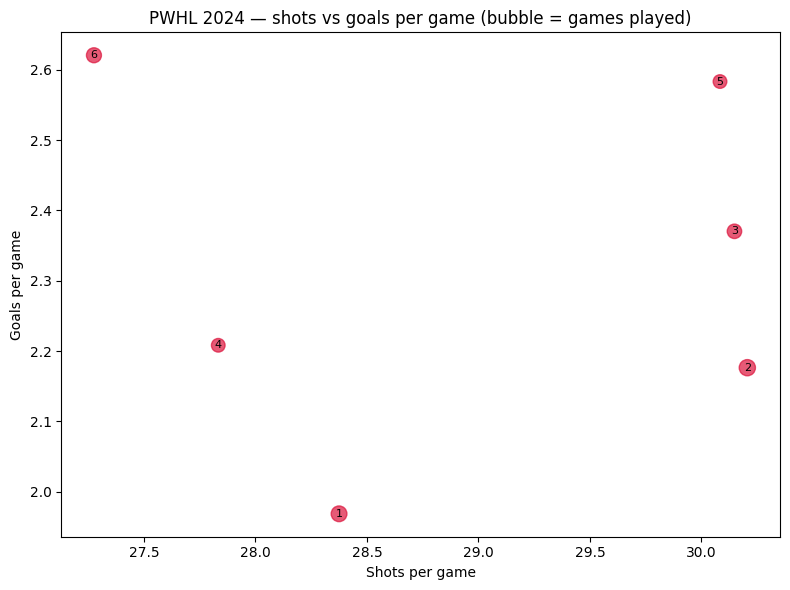

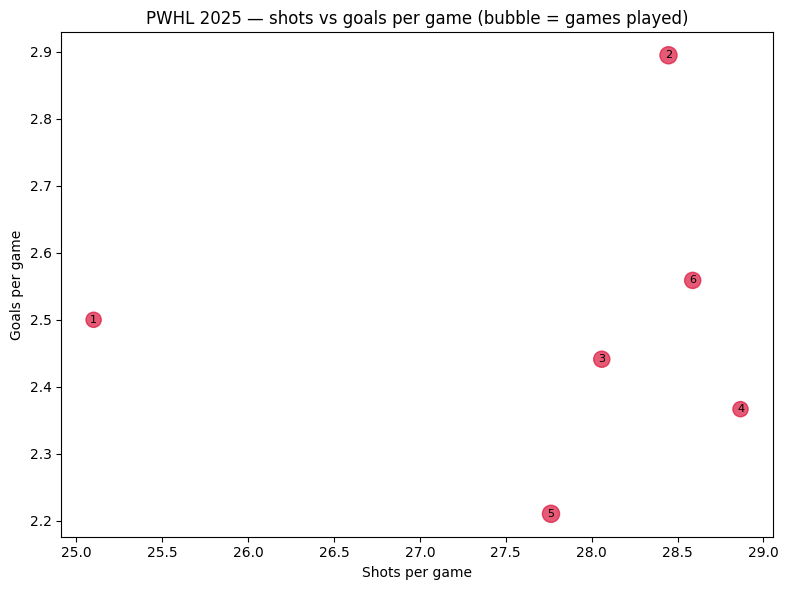

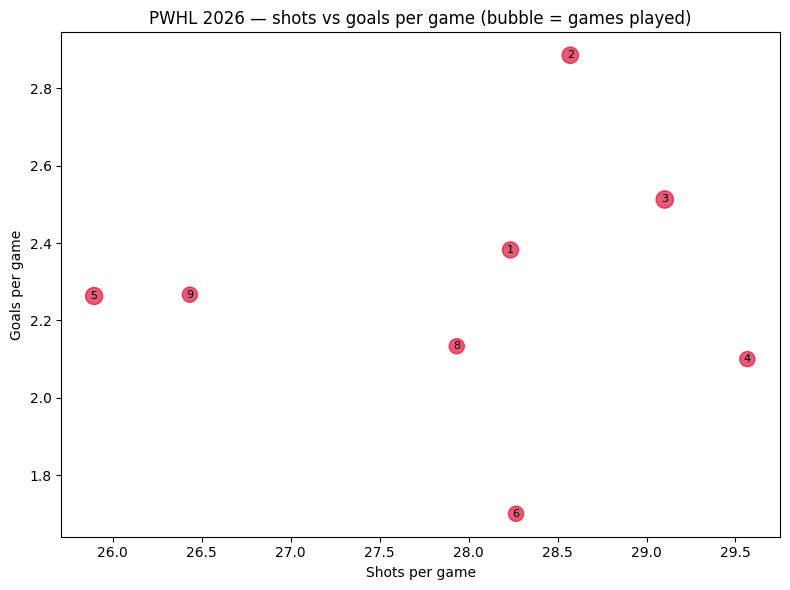

In [20]:
def shots_vs_goals(team_box, season_label):
    # per-team per-game averages
    agg = (team_box.groupby("team_id")
                   .agg(shots_pg=("shots", "mean"),
                        goals_pg=("goals", "mean"),
                        games=("game_id", "nunique"))
                   .reset_index())

    fig, ax = plt.subplots(figsize=(8, 6))
    sc = ax.scatter(agg["shots_pg"], agg["goals_pg"],
                    s=agg["games"] * 4, alpha=0.7, color="crimson")
    for _, r in agg.iterrows():
        ax.annotate(str(int(r["team_id"])),
                    (r["shots_pg"], r["goals_pg"]),
                    fontsize=8, ha="center", va="center")
    ax.set_xlabel("Shots per game")
    ax.set_ylabel("Goals per game")
    ax.set_title(f"{season_label} — shots vs goals per game (bubble = games played)")
    plt.tight_layout(); plt.show()

for yr, d in [("2024", pwhl_2024), ("2025", pwhl_2025), ("2026", pwhl_2026)]:
    shots_vs_goals(d["team_boxscores"], f"PWHL {yr}")

/tmp/ipykernel_6660/2224625983.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=["home", "away"])
/tmp/ipykernel_6660/2224625983.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data2, labels=["home", "away"])


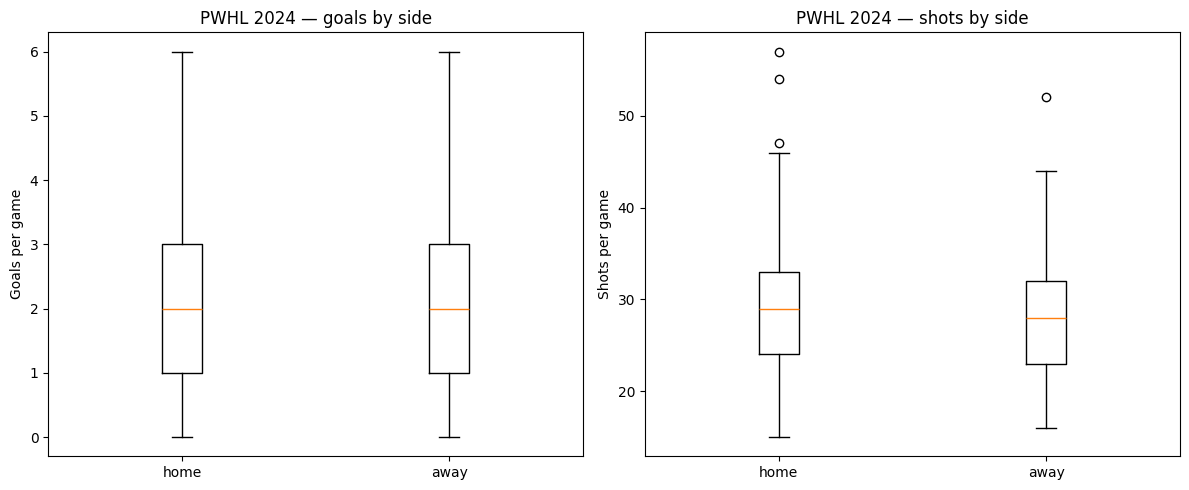

      goals  shots
side              
away   2.20  28.12
home   2.41  29.88


/tmp/ipykernel_6660/2224625983.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=["home", "away"])
/tmp/ipykernel_6660/2224625983.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data2, labels=["home", "away"])


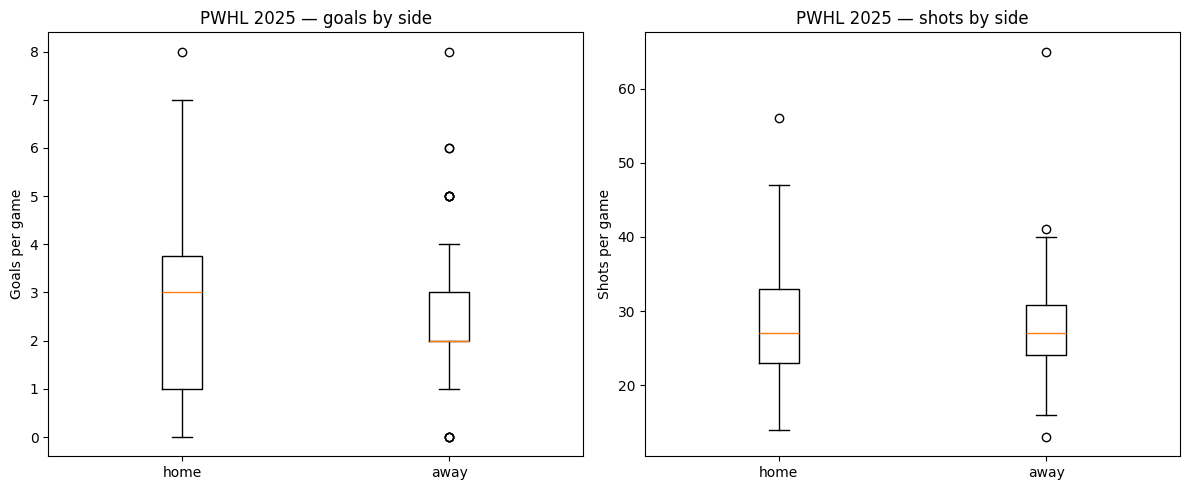

      goals  shots
side              
away   2.45  27.64
home   2.55  28.06


/tmp/ipykernel_6660/2224625983.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=["home", "away"])
/tmp/ipykernel_6660/2224625983.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data2, labels=["home", "away"])


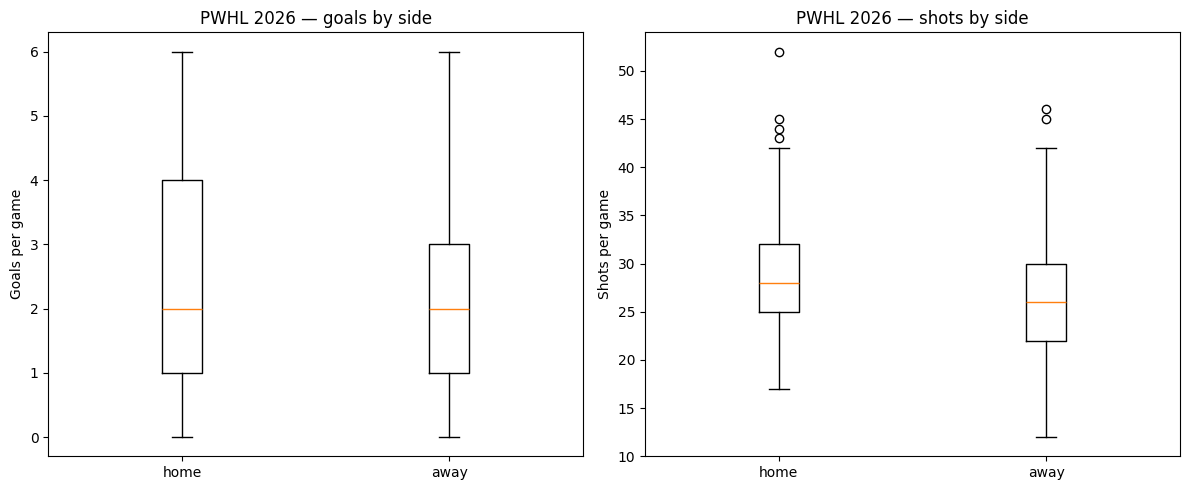

      goals  shots
side              
away   2.07  26.84
home   2.53  29.14


In [21]:
def home_away_goals(team_box, season_label):
    tb = team_box.copy()
    # team_side is typically 'home'/'away'/'neutral'
    tb["side"] = tb["team_side"].astype(str).str.lower().str.strip()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # left: box plot of goals by side
    data = [tb.loc[tb["side"] == s, "goals"].dropna() for s in ["home", "away"]]
    axes[0].boxplot(data, labels=["home", "away"])
    axes[0].set_ylabel("Goals per game")
    axes[0].set_title(f"{season_label} — goals by side")

    # right: shots by side
    data2 = [tb.loc[tb["side"] == s, "shots"].dropna() for s in ["home", "away"]]
    axes[1].boxplot(data2, labels=["home", "away"])
    axes[1].set_ylabel("Shots per game")
    axes[1].set_title(f"{season_label} — shots by side")

    plt.tight_layout(); plt.show()

    # numeric summary to quote in the report
    print(tb.groupby("side")[["goals", "shots"]].mean().round(2))

for yr, d in [("2024", pwhl_2024), ("2025", pwhl_2025), ("2026", pwhl_2026)]:
    home_away_goals(d["team_boxscores"], f"PWHL {yr}")

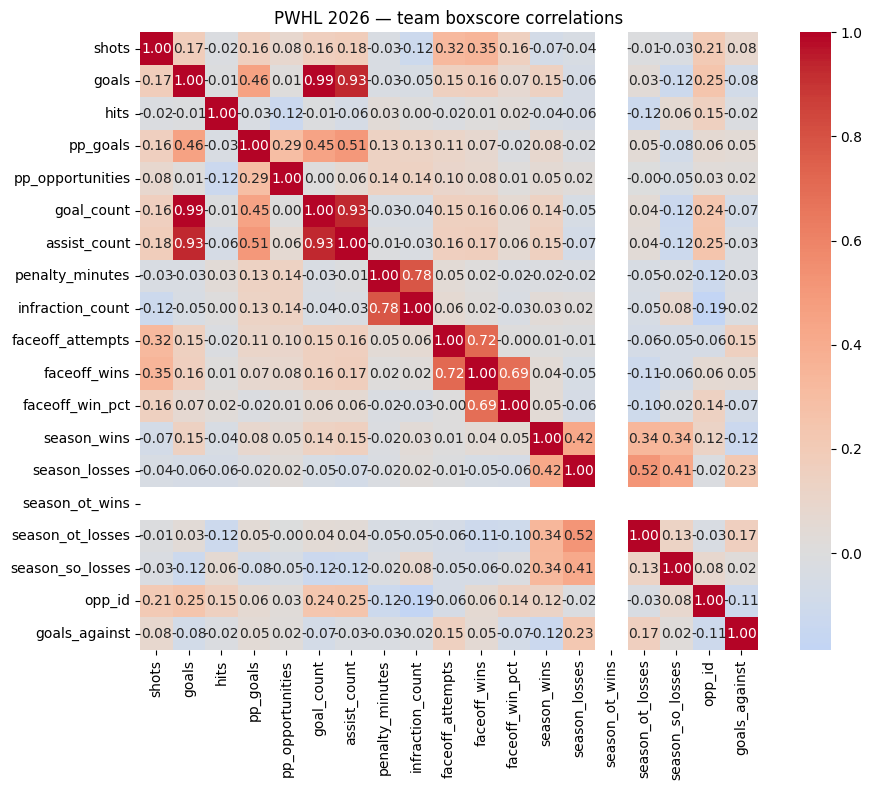

In [22]:
# correlation heatmap — screens all columns for redundancy + signal
import seaborn as sns

def corr_heatmap(team_box, label):
    tb = team_box.copy()
    if "goals_against" not in tb.columns:
        opp = tb[["game_id","team_id","goals"]].rename(
            columns={"team_id":"opp_id","goals":"goals_against"})
        tb = tb.merge(opp, on="game_id", how="left")
        tb = tb[tb["team_id"] != tb["opp_id"]]
    num = tb.select_dtypes("number").drop(columns=["game_id","team_id"], errors="ignore")
    plt.figure(figsize=(10,8))
    sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
    plt.title(f"{label} — team boxscore correlations")
    plt.tight_layout(); plt.show()

corr_heatmap(pwhl_2026["team_boxscores"], "PWHL 2026")

### Setting Up for ML Training

In [49]:
def build_team_game_table(game_info, team_box, sched, scoring_summary, season):
    """Raw season tables -> one row per team-game, with pre-game features and a single `win` target."""
    game_info = game_info.copy(); team_box = team_box.copy(); sched = sched.copy()

    for df in (game_info, team_box, sched):
        df["game_id"] = df["game_id"].astype(str)

    # --- long team-game frame with date, home/away ids ---
    tb = team_box.merge(
        sched[["game_id","game_date","home_team_id","away_team_id"]],
        on="game_id", how="left"
    ).sort_values(["team_id","game_date"])

    for c in ("team_id","home_team_id","away_team_id"):
        tb[c] = tb[c].astype(str)

    # --- rolling goals/shots (shifted, so current game excluded) ---
    for col in ["goals","shots"]:
        tb[f"{col}_roll5"] = (tb.groupby("team_id")[col]
            .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))

    # --- rest + back-to-back ---
    tb["days_rest"] = tb.groupby("team_id")["game_date"].transform(lambda s: s.diff().dt.days)
    tb["days_rest"] = tb["days_rest"].clip(upper=7)          # cap the league-wide breaks
    tb["b2b"] = (tb["days_rest"] == 1).astype(int)

    # --- distinct scorers, shifted + rolled ---
    ss = scoring_summary.copy()
    ss["game_id"] = ss["game_id"].astype(str)
    ss["team_id"] = ss["team_id"].astype(str)
    scorers = (ss.groupby(["game_id","team_id"])["scorer_id"]
                 .nunique().reset_index()
                 .rename(columns={"scorer_id":"n_scorers"}))
    tb = tb.merge(scorers, on=["game_id","team_id"], how="left")
    tb["n_scorers"] = tb["n_scorers"].fillna(0)
    tb["n_scorers_roll5"] = (tb.groupby("team_id")["n_scorers"]
        .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))

    # --- attach outcome (post-game, for the target only) ---
    gi = game_info[["game_id","home_score","away_score"]].copy()
    tb = tb.merge(gi, on="game_id", how="left")
    tb["goals_for"]     = tb["goals"].where(tb["team_id"] == tb["home_team_id"], tb["goals"])
    tb["goals_against"] = tb["home_score"] + tb["away_score"] - tb["goals_for"]

    # --- engineered features ---
    tb["sh_pct"]   = tb["goals_roll5"] / tb["shots_roll5"].replace(0, pd.NA)
    tb["is_home"]  = (tb["team_id"] == tb["home_team_id"]).astype(int)
    tb["win"]      = (tb["goals_for"] > tb["goals_against"]).astype(int)
    tb["season"]   = season

    keep = ["game_id","season","team_id","is_home","win","goals_for","goals_against",
            "goals_roll5","shots_roll5","sh_pct","days_rest","b2b","n_scorers_roll5"]
    return tb[keep].reset_index(drop=True)


pwhl_games = pd.concat([
    build_team_game_table(
        d["game_info"], d["team_boxscores"], d["schedules"],
        d["scoring_summary"].to_pandas() if hasattr(d["scoring_summary"], "to_pandas") else d["scoring_summary"],
        y,
    )
    for y, d in [(2024, pwhl_2024), (2025, pwhl_2025), (2026, pwhl_2026)]
], ignore_index=True)

print(pwhl_games.shape)
print(pwhl_games["win"].mean())
print(pwhl_games.isnull().sum())
print(pwhl_games.head())

(640, 13)
0.5
game_id             0
season              0
team_id             0
is_home             0
win                 0
goals_for           0
goals_against       0
goals_roll5        20
shots_roll5        20
sh_pct             20
days_rest          20
b2b                 0
n_scorers_roll5    20
dtype: int64
  game_id  season team_id  is_home  win  goals_for  goals_against  \
0       4    2024       1        1    0          2              3   
1      11    2024       1        0    1          3              2   
2      14    2024       1        0    1          3              2   
3      16    2024       1        1    0          1              4   
4      19    2024       1        0    1          3              2   

   goals_roll5  shots_roll5    sh_pct  days_rest  b2b  n_scorers_roll5  
0          NaN          NaN       NaN        NaN    0              NaN  
1     2.000000        35.00  0.057143        7.0    0         2.000000  
2     2.500000        28.00  0.089286        4.0    0

In [50]:
print(pwhl_games.groupby("game_id")[["goals_for","goals_against"]].sum().head())

         goals_for  goals_against
game_id                          
10               6              6
105              4              4
106              7              7
107              7              7
108              5              5


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
# --- feature list ---
feature_cols = ["goals_roll5","shots_roll5","days_rest","b2b","is_home"]

for bad in ("win","goals_for","goals_against","game_id","season"):
    assert bad not in feature_cols

df = pwhl_games.dropna(subset=feature_cols).reset_index(drop=True)
X = df[feature_cols]
y = df["win"]
groups = df["game_id"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- fit on train only ---
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

logreg_pred = model.predict(X_test)

In [52]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [53]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    random_state=42, eval_metric="logloss", verbosity=0
)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)


In [54]:
from sklearn.svm import SVC

svc = SVC(kernel="rbf", probability=True, random_state=42)
svc.fit(X_train, y_train)

svc_pred = svc.predict(X_test)

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

def evaluate_model(model_name, y_test, y_pred):
    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall    = recall_score(y_test, y_pred, zero_division=0)

    print(f"\n{model_name} Performance:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")

    return accuracy, precision, recall

# evaluate
lr_acc,  lr_prec,  lr_rec  = evaluate_model("Logistic Regression", y_test, logreg_pred)
rf_acc,  rf_prec,  rf_rec  = evaluate_model("Random Forest", y_test, rf_pred)
xgb_acc, xgb_prec, xgb_rec = evaluate_model("XGBoost", y_test, xgb_pred)
svc_acc, svc_prec, svc_rec = evaluate_model("SVC (RBF)", y_test, svc_pred)


Logistic Regression Performance:
  Accuracy:  0.5565
  Precision: 0.5660
  Recall:    0.4839

Random Forest Performance:
  Accuracy:  0.4597
  Precision: 0.4615
  Recall:    0.4839

XGBoost Performance:
  Accuracy:  0.5242
  Precision: 0.5231
  Recall:    0.5484

SVC (RBF) Performance:
  Accuracy:  0.4516
  Precision: 0.4375
  Recall:    0.3387


In [56]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
d_acc, d_prec, d_rec = evaluate_model("Always predict majority", y_test, dummy_pred)


Always predict majority Performance:
  Accuracy:  0.5000
  Precision: 0.0000
  Recall:    0.0000


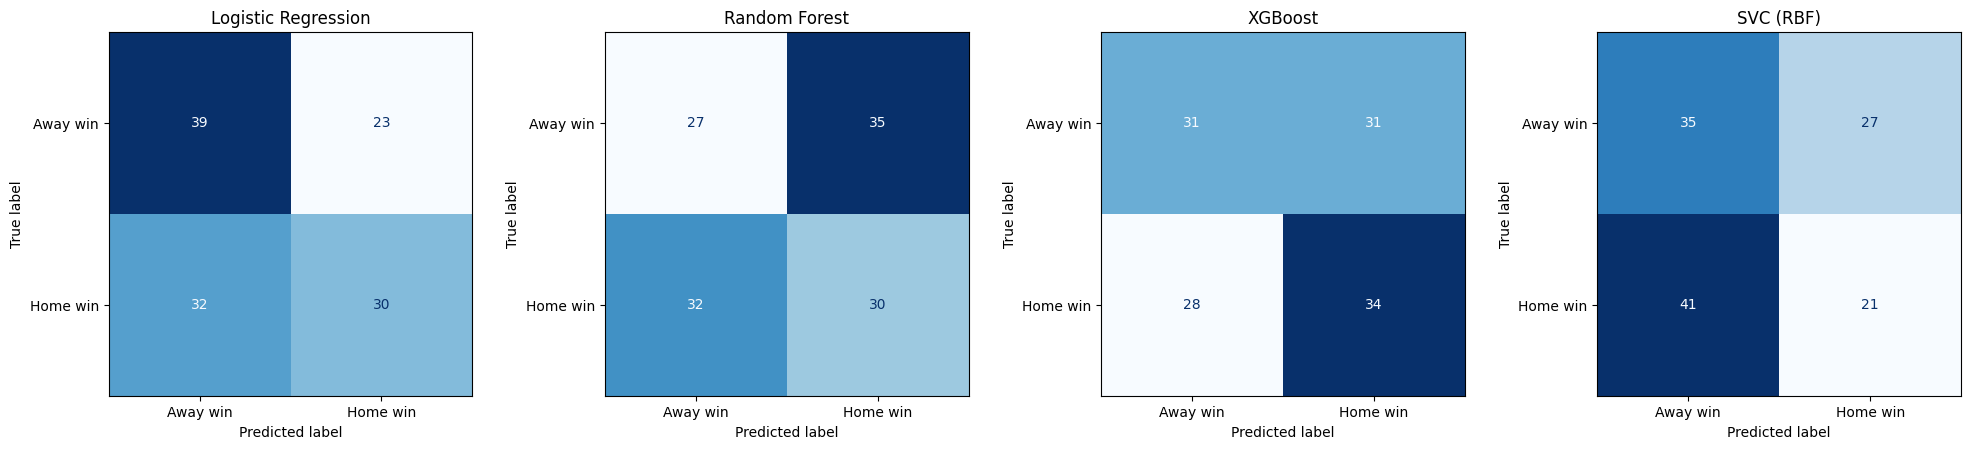

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models_preds = {
    "Logistic Regression": logreg_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "SVC (RBF)": svc_pred,
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, pred) in zip(axes, models_preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

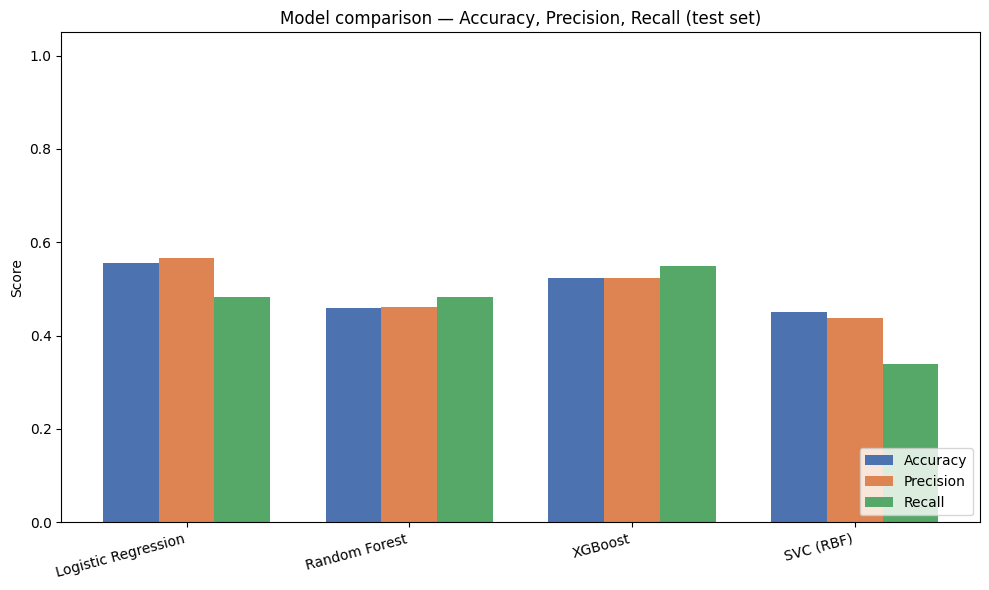

In [58]:
import numpy as np
import matplotlib.pyplot as plt

model_names = ["Logistic Regression", "Random Forest", "XGBoost", "SVC (RBF)"]
accuracy = [lr_acc,  rf_acc,  xgb_acc,  svc_acc]
precision = [lr_prec, rf_prec, xgb_prec, svc_prec]
recall = [lr_rec,  rf_rec,  xgb_rec,  svc_rec]

x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width, accuracy, width, label="Accuracy", color="#4C72B0")
ax.bar(x, precision, width, label="Precision", color="#DD8452")
ax.bar(x + width, recall, width, label="Recall", color="#55A868")

ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison — Accuracy, Precision, Recall (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

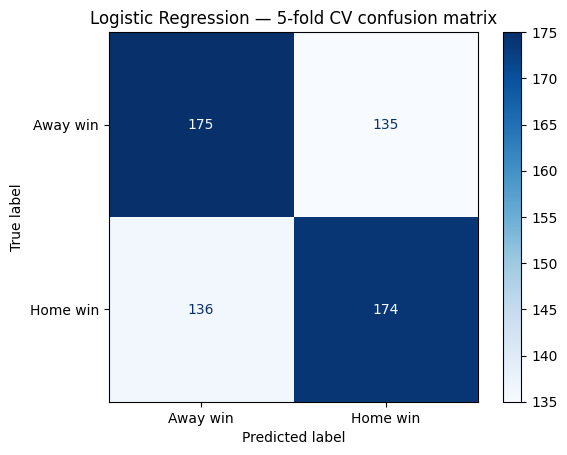

In [59]:
from sklearn.model_selection import cross_val_predict
cv_pred = cross_val_predict(LogisticRegression(max_iter=1000), X, y, cv=5)
cm = confusion_matrix(y, cv_pred)
ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"]).plot(cmap="Blues")
plt.title("Logistic Regression — 5-fold CV confusion matrix")
plt.show()